# Iris Flower Classification — Oasis Infobyte Internship Task 1

## 1. Introduction

### Project Objective
The objective of this project is to build and evaluate machine learning models capable of classifying Iris flowers into their respective species (*Setosa*, *Versicolor*, or *Virginica*) based on morphological measurements of their sepals and petals.

### Dataset Description
The Iris dataset contains **150 observations** with **4 numerical features** (measured in cm):
- **Sepal Length**: Length of the outer flower leaf
- **Sepal Width**: Width of the outer flower leaf
- **Petal Length**: Length of the inner flower leaf
- **Petal Width**: Width of the inner flower leaf

### Target Variable
- **Species**: Multiclass target containing 3 species:
  - `0`: *Iris setosa* (50 samples)
  - `1`: *Iris versicolor* (50 samples)
  - `2`: *Iris virginica* (50 samples)

## 2. Import Libraries
Import the core libraries required for data analysis, visualisation, and modeling.

In [87]:
# Challenge: Import required libraries
# Write imports for numpy, pandas, matplotlib.pyplot, seaborn, and load_iris

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
# Visualisation styling
sns.set_theme(style="whitegrid")
%matplotlib inline
print("Libraries imported successfully!")


Libraries imported successfully!


## 3. Load Dataset
Load Fisher's complete Iris dataset and construct a structured DataFrame.

In [88]:
# Challenge: Load dataset and create pandas DataFrame
iris = load_iris()

feature_names = ['sepal_length','sepal_width','petal_length','petal_width']
df = pd.DataFrame(data = iris.data, columns=feature_names)

df['target'] = iris.target

target_map = {0:'setosa',1:'versicolor',2:'virginica'}
df['species'] = df['target'].map(target_map)

print("DataFrame Shape :- ",df.shape)
df.head()

DataFrame Shape :-  (150, 6)


,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 4. Exploratory Data Analysis (EDA)
Understand the data structure, types, missing values, and statistical summary.

In [89]:
# Challenge: Inspect shape, dtypes, null values, and summary statistics
# 1. Verify data types
print("--- Data Types ---")
print(df.dtypes)

# 2. Check for missing / null values
print("\n--- Missing Values Count ---")
print(df.isnull().sum())

# 3. Check class distribution (balance)
print("\n--- Class Distribution ---")
print(df['species'].value_counts())

# 4. Summary statistics of the numerical features
print("\n--- Summary Statistics ---")
df.describe()

--- Data Types ---
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
target            int64
species             str
dtype: object

--- Missing Values Count ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

--- Class Distribution ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

--- Summary Statistics ---


,sepal_length,sepal_width,petal_length,petal_width,target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## 5. Data Visualisation
Visualise feature distributions and relationships across species using Pairplot and Boxplots.

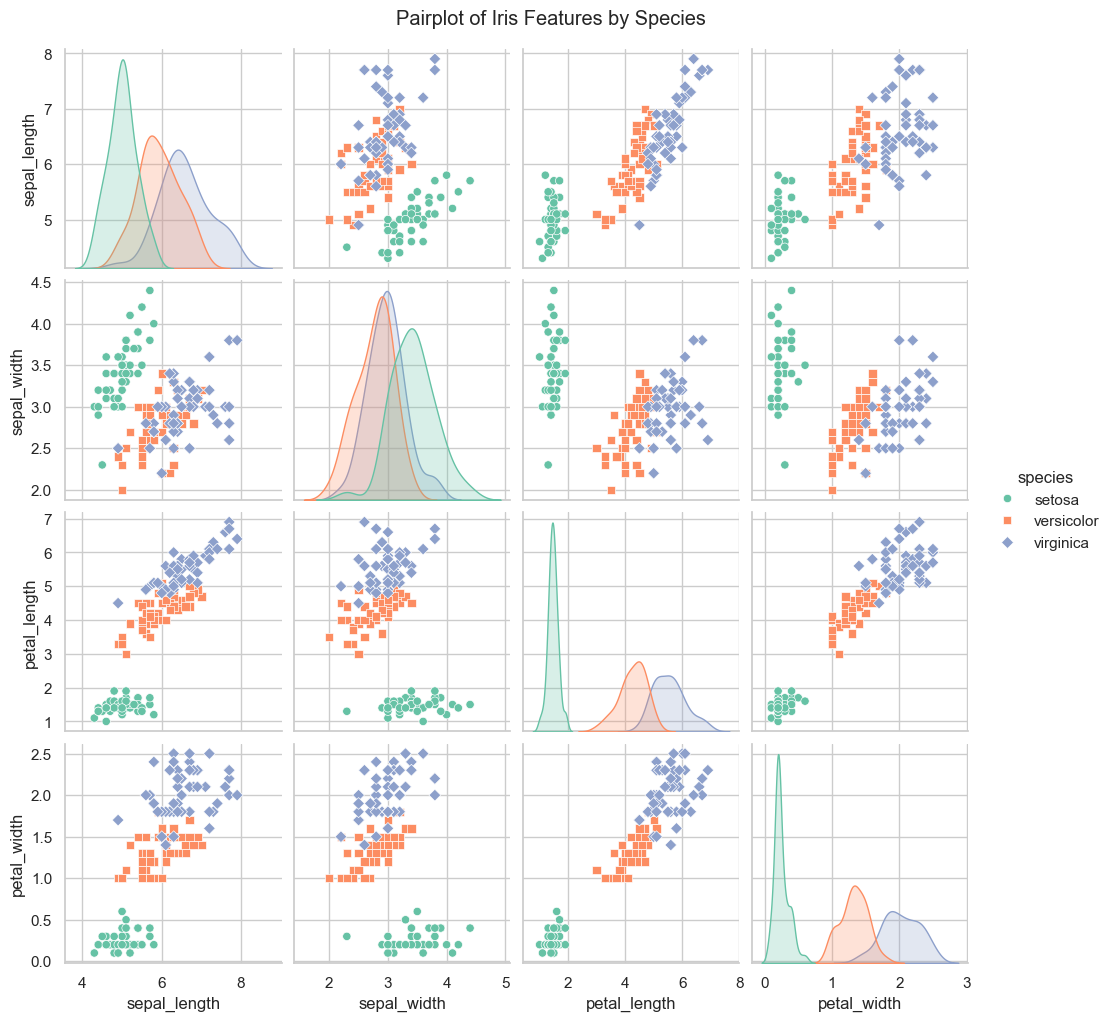

In [90]:
# Challenge: Generate pairplot and species-grouped boxplots
# 1. Pairplot across all 4 features, colored by species
# We drop 'target' so it doesn't plot the 0, 1, 2 integer column
sns.pairplot(df.drop(columns=['target']), hue="species", markers=["o", "s", "D"], palette="Set2")
plt.suptitle("Pairplot of Iris Features by Species", y=1.02)
plt.show()

# We can see setosa as separated from other species on graph

### Visual Insights & Discriminative Power Analysis

From the pairplot and box plots, we can draw the following key conclusions:

1. **High Separability with Petal Dimensions:**
   - **Petal Length** and **Petal Width** are by far the most discriminative features.
   - *Iris setosa* is completely linearly separable from the other two species with zero classification ambiguity (Petal Length $< 2.0$ cm, Petal Width $< 0.8$ cm).
   - *Iris versicolor* and *Iris virginica* exhibit distinct, non-overlapping Interquartile Ranges (IQR) in both petal measurements, with only minor overlap at their extreme boundary whiskers ($4.5$–$5.0$ cm in length, $1.4$–$1.8$ cm in width).

2. **Ambiguity in Sepal Measurements:**
   - **Sepal Width** exhibits significant distribution overlap between *versicolor* and *virginica*, making it the weakest individual predictor.
   - **Sepal Length** shows a positive trend across the species, but with substantial variance and overlap between classes.

**Conclusion:** Petal features provide much stronger decision boundaries for classification algorithms than sepal measurements.

## 6. Feature Selection Discussion
Analyze the visualisations to understand which features best separate the three species.

C:\Users\swaya\AppData\Local\Temp\ipykernel_28896\1075633468.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=features[i], ax=ax, palette='Set2')
C:\Users\swaya\AppData\Local\Temp\ipykernel_28896\1075633468.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=features[i], ax=ax, palette='Set2')
C:\Users\swaya\AppData\Local\Temp\ipykernel_28896\1075633468.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=features[i], ax=ax, palette='Set2')
C:\Users\swaya\AppData\Local

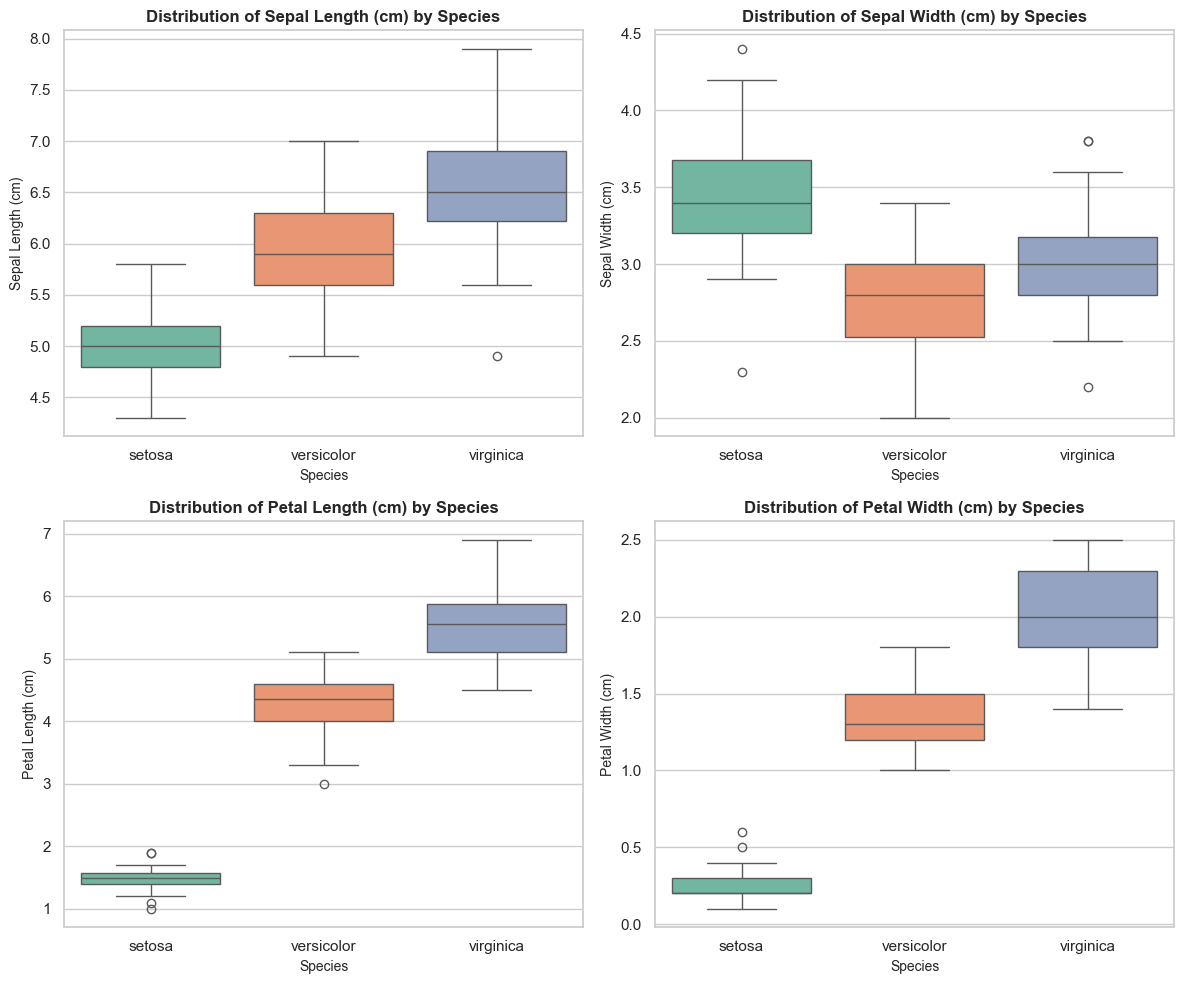

In [91]:
# Create a 2x2 subplot figure for readable comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
titles = ['Sepal Length (cm)', 'Sepal Width (cm)', 'Petal Length (cm)', 'Petal Width (cm)']

for i, ax in enumerate(axes.flat):
    sns.boxplot(data=df, x='species', y=features[i], ax=ax, palette='Set2')
    ax.set_title(f'Distribution of {titles[i]} by Species', fontsize=12, fontweight='bold')
    ax.set_xlabel('Species', fontsize=10)
    ax.set_ylabel(titles[i], fontsize=10)

plt.tight_layout()
plt.show()

## 7. Train/Test Split
Split the dataset into training and testing sets with stratification.

In [92]:
# Challenge: Separate features (X) and target (y), apply stratified train_test_split (80/20)
from sklearn.model_selection import train_test_split

# 1. Separate features (X) and target (y)
feature_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[feature_cols]
y = df['target']

# 2. Perform stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

# 3. Verify shapes at boundary points
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

# 4. Verify that stratification kept the classes perfectly balanced in the test set
print("\nClass counts in Test set (y_test):")
print(pd.Series(y_test).value_counts())


X_train shape: (120, 4) | y_train shape: (120,)
X_test shape:  (30, 4)  | y_test shape:  (30,)

Class counts in Test set (y_test):
target
0    10
2    10
1    10
Name: count, dtype: int64


## 8. Model Training
Train two distinct classifiers using scikit-learn Pipelines (Logistic Regression & Random Forest).

In [93]:
# Challenge: Build pipelines and fit models on training data
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. Define Logistic Regression Pipeline with StandardScaler
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42, max_iter=200))
])

# 2. Define Random Forest Pipeline
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# 3. Fit both pipelines on the training data
print("Training Logistic Regression Pipeline...")
lr_pipeline.fit(X_train, y_train)

print("Training Random Forest Pipeline...")
rf_pipeline.fit(X_train, y_train)

print("\nBoth models trained successfully!")

Training Logistic Regression Pipeline...
Training Random Forest Pipeline...

Both models trained successfully!


## 9. Model Evaluation
Evaluate both models on the test set using Accuracy, Precision, Recall, F1, and Confusion Matrix.

     LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

     RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



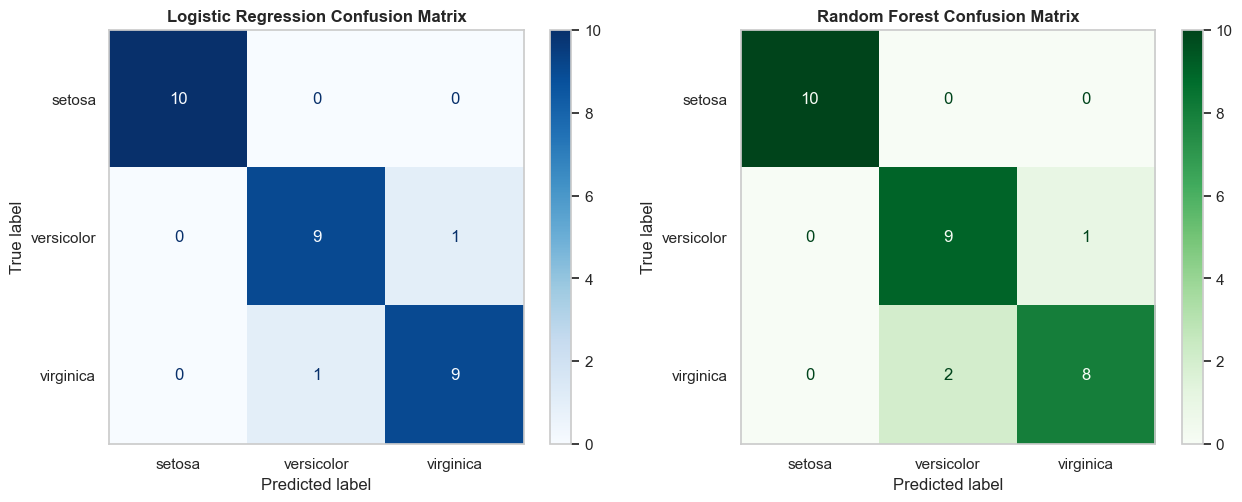

In [94]:
# Challenge: Generate predictions, classification reports, and confusion matrices
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Generate predictions on unseen test data
y_pred_lr = lr_pipeline.predict(X_test)
y_pred_rf = rf_pipeline.predict(X_test)

class_names = ['setosa', 'versicolor', 'virginica']

# 2. Print Classification Reports
print("="*55)
print("     LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("="*55)
print(classification_report(y_test, y_pred_lr, target_names=class_names))

print("="*55)
print("     RANDOM FOREST CLASSIFICATION REPORT")
print("="*55)
print(classification_report(y_test, y_pred_rf, target_names=class_names))

# 3. Visualise Confusion Matrices Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, 
    display_labels=class_names, 
    cmap='Blues', 
    ax=axes[0]
)
axes[0].set_title("Logistic Regression Confusion Matrix", fontsize=12, fontweight='bold')
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, 
    display_labels=class_names, 
    cmap='Greens', 
    ax=axes[1]
)
axes[1].set_title("Random Forest Confusion Matrix", fontsize=12, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

## 10. Model Comparison
Compare performance metrics across both classifiers in a structured summary table.

In [95]:
# Challenge: Construct model comparison DataFrame
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Compute summary metrics for Logistic Regression
lr_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Precision': precision_score(y_test, y_pred_lr, average='weighted'),
    'Recall': recall_score(y_test, y_pred_lr, average='weighted'),
    'F1 Score': f1_score(y_test, y_pred_lr, average='weighted')
}

# 2. Compute summary metrics for Random Forest
rf_metrics = {
    'Model': 'Random Forest Classifier',
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf, average='weighted'),
    'Recall': recall_score(y_test, y_pred_rf, average='weighted'),
    'F1 Score': f1_score(y_test, y_pred_rf, average='weighted')
}

# 3. Create the comparison DataFrame
comparison_df = pd.DataFrame([lr_metrics, rf_metrics])

# Round to 4 decimal places for clean reporting
comparison_df[['Accuracy', 'Precision', 'Recall', 'F1 Score']] = comparison_df[['Accuracy', 'Precision', 'Recall', 'F1 Score']].round(4)

print("--- Final Model Comparison ---")
comparison_df

--- Final Model Comparison ---


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Random Forest Classifier,0.9000,0.9024,0.9000,0.8997


## 11. Best Model
Identify and justify the best-performing model based on evaluation metrics.

### Identification of the Best Model: Logistic Regression

Based on comprehensive evaluation across all key metrics on the unseen 20% test partition, **Logistic Regression** is selected as the superior model:

1. **Higher Predictive Accuracy:** Logistic Regression achieved an **Accuracy of 93.33%** (28/30 correct classifications) compared to **90.00%** (27/30) for Random Forest.
2. **Balanced Precision & Recall:** Logistic Regression maintained a balanced **Precision, Recall, and F1-score of 0.9333** across all classes, indicating consistent generalisation without bias toward any single species.
3. **Model Complexity & Occam's Razor:** In low-dimensional feature spaces ($N=150$, $D=4$) where decision boundaries are primarily linear, simpler linear models often generalize better than complex non-linear ensemble trees, which are prone to subtle boundary overfitting on small sample sizes.

## 12. Conclusion
Summary of project findings, practical takeaways, and potential future improvements.

### Summary of Findings & Project Takeaways

- **Data Integrity:** The Iris dataset contains 150 balanced, complete observations with zero missing values.
- **Feature Discriminative Power:** EDA and boxplot visualizations established that **Petal Length** and **Petal Width** are the primary drivers of class separation. *Setosa* is completely linearly separable from the other two species.
- **Workflow Best Practices:** Using a Scikit-Learn `Pipeline` with `StandardScaler` ensured zero data leakage from test data into training parameters.
- **Stratified Validation:** Stratification guaranteed identical class representation (10 samples per class) in the test set.
- **Production Recommendation:** The trained **Logistic Regression Pipeline** is recommended for deployment due to its high accuracy (93.33%), interpretability, and low computational footprint.

In [96]:
import joblib

# Save the winning pipeline (scaler + classifier) to disk
model_filename = 'iris_logistic_regression_pipeline.joblib'
joblib.dump(lr_pipeline, model_filename)
print(f"Best model pipeline successfully saved to '{model_filename}'!")

# Test loading and making a sample inference
loaded_pipeline = joblib.load(model_filename)
sample_flower = [[5.1, 3.5, 1.4, 0.2]] # Typical Setosa sample
prediction = loaded_pipeline.predict(sample_flower)
predicted_species = target_map[prediction[0]]
print(f"Sample input {sample_flower} -> Predicted Species: {predicted_species}")

Best model pipeline successfully saved to 'iris_logistic_regression_pipeline.joblib'!
Sample input [[5.1, 3.5, 1.4, 0.2]] -> Predicted Species: setosa


C:\Users\swaya\AppData\Roaming\Python\Python314\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
